# Primavera silenciosa: el DDT contado con datos

**Capítulo del curso:** Contar historias con datos (Open-Ended Project 5)

En 1944 el pesticida DDT llegó al público como un "milagro" contra los insectos. En 1962, Rachel Carson publicó
*Silent Spring* y mostró que también dañaba a las aves. Cuento la historia en tres gráficas:

1. Las palabras de **insectos** se usan cada vez menos desde 1944.
2. La cáscara de los huevos del gavilán se adelgaza justo después.
3. Las palabras de **aves** se recuperan tras el libro y la prohibición.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = Path("figuras")
FIG.mkdir(exist_ok=True)

In [2]:
palabras = pd.read_csv("datos/animal-word-trends-silent-spring.csv")
huevos = pd.read_csv("datos/sparrowhawk-eggshell-data.csv")

INSECTOS = ["mosquito", "louse", "flea", "bedbug"]
AVES = ["robin", "peregrine", "osprey", "sparrowhawk"]

tabla = palabras.pivot(index="year", columns="word", values="frequency")

def indice(columnas, base):
    # Frecuencia relativa a la media de los cinco años anteriores a `base` (=100).
    referencia = tabla.loc[base - 5:base - 1, columnas].mean()
    return tabla[columnas] / referencia * 100

## 1. Los insectos desde 1944

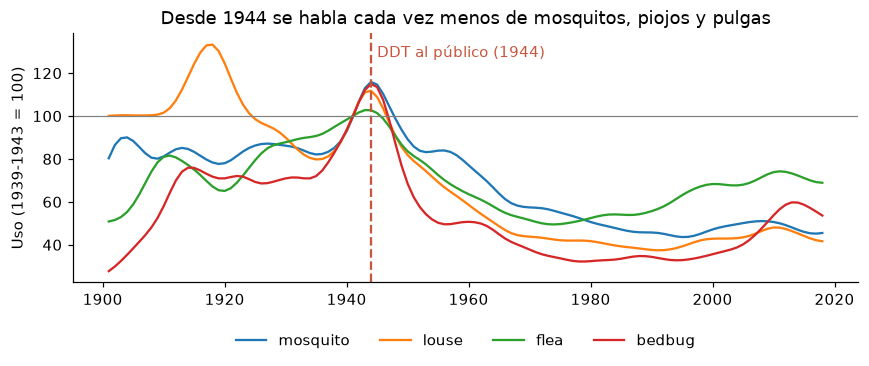

In [3]:
ins = indice(INSECTOS, 1944)
fig, ax = plt.subplots(figsize=(8, 3.5))
for palabra in INSECTOS:
    ax.plot(ins.index, ins[palabra].rolling(3, center=True).mean(), label=palabra)
ax.axvline(1944, color="#c8553d", ls="--")
ax.text(1945, ax.get_ylim()[1] * 0.92, "DDT al público (1944)", color="#c8553d")
ax.axhline(100, color="grey", lw=0.8)
ax.set_ylabel("Uso (1939-1943 = 100)")
ax.set_title("Desde 1944 se habla cada vez menos de mosquitos, piojos y pulgas")
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.15))
fig.tight_layout()
fig.savefig(FIG / "insectos.png", bbox_inches="tight")
plt.show()

## 2. La cáscara de los huevos

Índice medio antes de 1947: 1.41 · desde 1947: 1.16 (-18 %)


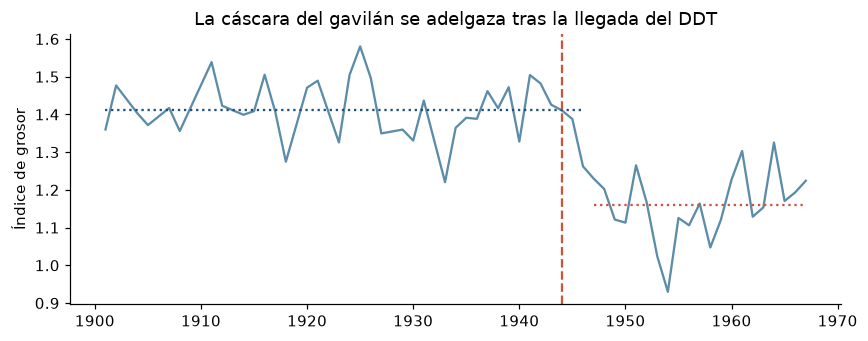

In [4]:
antes = huevos[huevos["year"] < 1947]["avg_thickness"].mean()
despues = huevos[huevos["year"] >= 1947]["avg_thickness"].mean()
print(f"Índice medio antes de 1947: {antes:.2f} · desde 1947: {despues:.2f} ({(despues / antes - 1) * 100:.0f} %)")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(huevos["year"], huevos["avg_thickness"], color="#5c8ca8")
ax.hlines(antes, huevos["year"].min(), 1946, color="#1f4e79", ls=":")
ax.hlines(despues, 1947, huevos["year"].max(), color="#c8553d", ls=":")
ax.axvline(1944, color="#c8553d", ls="--")
ax.set_ylabel("Índice de grosor")
ax.set_title("La cáscara del gavilán se adelgaza tras la llegada del DDT")
fig.tight_layout()
fig.savefig(FIG / "cascara-huevo.png", bbox_inches="tight")
plt.show()

## 3. Las aves después de *Silent Spring*

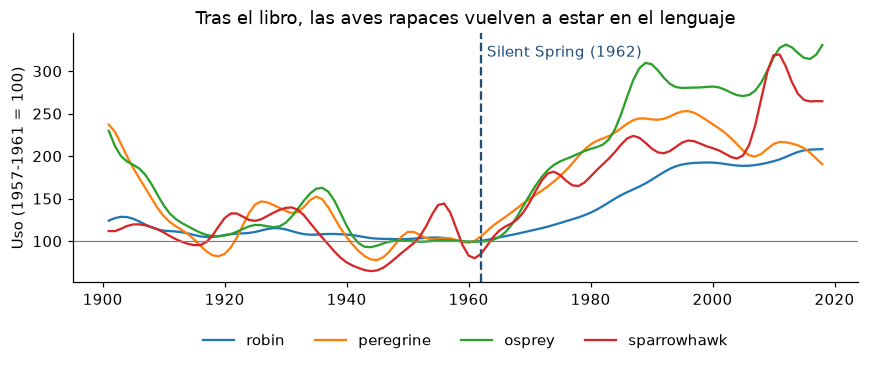

In [5]:
av = indice(AVES, 1962)
fig, ax = plt.subplots(figsize=(8, 3.5))
for palabra in AVES:
    ax.plot(av.index, av[palabra].rolling(3, center=True).mean(), label=palabra)
ax.axvline(1962, color="#1f4e79", ls="--")
ax.text(1963, ax.get_ylim()[1] * 0.92, "Silent Spring (1962)", color="#1f4e79")
ax.axhline(100, color="grey", lw=0.8)
ax.set_ylabel("Uso (1957-1961 = 100)")
ax.set_title("Tras el libro, las aves rapaces vuelven a estar en el lenguaje")
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.15))
fig.tight_layout()
fig.savefig(FIG / "aves.png", bbox_inches="tight")
plt.show()

## Conclusiones

- **Insectos:** mosquito, piojo y pulga se usan cada vez menos desde 1944. Hacia 1975-1985, "mosquito" se usaba
  la mitad que antes del DDT.
- **Huevos:** el índice de grosor de la cáscara del gavilán baja de 1,41 a 1,16 (un 18 % menos) desde 1947. Las
  cáscaras finas se rompían y las aves dejaban de criar.
- **Aves:** tras *Silent Spring* y las prohibiciones del DDT en los años 70, "peregrine", "osprey" y "sparrowhawk"
  se usan más que nunca, en paralelo a la recuperación de esas especies.
- **Ojo:** que se use una palabra no mide cuántos animales hay, y una correlación en el tiempo no prueba la causa.
  La historia es sólida porque los datos del huevo y el contexto histórico apuntan en la misma dirección.